# C02-DB — DBSCAN (RFM + AOV + Diversity + QtyPerOrder → log1p mọi biến → StandardScaler → PCA 90%)

Thí nghiệm **C02-DB** (người chạy: Thuận, hạn nội bộ 18/11/2026) theo chiến lược model. So với C01 (RFM + AOV + Diversity), **chỉ thêm QtyPerOrder** (số lượng hàng trung bình mỗi đơn). Quy trình: làm sạch → feature cấp khách → RFM + AOV + Diversity + QtyPerOrder → log1p mọi biến → StandardScaler → PCA 90% → DBSCAN. Đây là nhóm C; C02, C03, C04 so với C01 (RFM + AOV + Diversity).

Nguồn biến trong `customer_features.csv` của nhóm: AOV = `avg_order_value`, Diversity = `n_stock_codes`, QtyPerOrder = `avg_quantity_per_order`, Tenure = `observed_span_days` (ngày mua cuối − ngày mua đầu, theo mô tả của chiến lược; khác `observed_tenure_days` = ngày tham chiếu − ngày mua đầu).

## Params

In [1]:
FEATURES = ['Recency', 'Frequency', 'Monetary', 'AOV', 'Diversity', 'QtyPerOrder']
FEATURES_PARENT = ['Recency', 'Frequency', 'Monetary', 'AOV', 'Diversity']   # C01, để đối chiếu cùng tham số
RANDOM_STATE = 42
MIN_SAMPLES_GRID = [4, 6, 8, 10, 15, 20]
EPS_GRID = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0]   # giống B01-DB (An)
MAX_NOISE = 0.05            # điều kiện chọn: nhiễu tối đa 5% số khách
MIN_CLUSTERS = 2            # điều kiện chọn: ít nhất 2 cụm (không tính nhiễu)

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01-DB, A02-KM, A02-GN, B01-GN...)
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

# Đổi tên cột cho dễ đọc: AOV, Diversity, QtyPerOrder, Tenure
RENAME = {"avg_order_value": "AOV", "n_stock_codes": "Diversity", "avg_quantity_per_order": "QtyPerOrder", "observed_span_days": "Tenure"}
df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns=RENAME)
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
assert np.allclose(df["AOV"], df["Monetary"] / df["Frequency"], atol=0.01)              # AOV = Monetary / Frequency
assert np.allclose(df["QtyPerOrder"], df["total_quantity"] / df["Frequency"], atol=0.01)   # QtyPerOrder = tổng số lượng / số đơn
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 6)


,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder
count,4327.00,4327.00,4327.00,4327.00,4327.00,4327.0
mean,93.04,4.25,1944.95,372.40,61.49,227.4
std,99.98,7.64,8441.89,466.49,85.31,298.5
min,1.00,1.00,2.90,2.90,1.00,1.0
25%,18.00,1.00,301.52,175.47,16.00,93.0
50%,51.00,2.00,657.90,286.70,35.00,161.0
75%,143.00,5.00,1624.10,421.99,77.00,272.0
max,374.00,206.00,278748.02,14844.77,1784.00,7824.0


**Nhận xét:** 4,327 khách, dùng chung file feature của nhóm. Monetary lệch phải rất mạnh (trung vị 657.9, max 278,748) nên tiền xử lý ảnh hưởng nhiều đến kết quả.

## Độ lệch của các biến trước và sau `log1p`

In [3]:
skew = pd.DataFrame({"skew_raw": X.skew(), "skew_log1p": np.log1p(X).skew(), "zero_pct": (100 * (X == 0).mean()).round(2)}).round(2)
skew

,skew_raw,skew_log1p,zero_pct
Recency,1.25,-0.33,0.0
Frequency,11.95,1.21,0.0
Monetary,21.04,0.35,0.0
AOV,11.94,-0.00,0.0
Diversity,6.92,-0.24,0.0
QtyPerOrder,9.45,-0.38,0.0


**Nhận xét:** `log1p` kéo độ lệch của Monetary từ 21.04 xuống 0.35; độ lệch sau log1p của mọi biến nằm trong [-0.38; 1.21].

## Tiền xử lý

RFM + AOV + Diversity + QtyPerOrder → log1p mọi biến → StandardScaler → PCA 90%.

In [4]:
prep = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, validate=True)),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Z = prep.fit_transform(X.values)
print("Kích thước đầu vào mô hình:", Z.shape)
ev = prep["pca"].explained_variance_ratio_
print("Phương sai từng PC:", ev.round(4), "| giữ lại:", round(ev.sum(), 4))

Kích thước đầu vào mô hình: (4327, 3)
Phương sai từng PC: [0.5848 0.2359 0.0882] | giữ lại: 0.9089


## Quét lưới eps × min_samples

In [5]:
rows = []
for ms in MIN_SAMPLES_GRID:
    for eps in EPS_GRID:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
        core = lab != -1
        sizes = np.bincount(lab[core]) if core.any() else np.array([0])
        ncl = len(sizes) if core.any() else 0
        ok = ncl >= 2
        rows.append({"min_samples": ms, "eps": eps, "n_clusters": ncl, "noise_pct": round(100 * (~core).mean(), 2),
                     "largest_pct": round(100 * sizes.max() / len(lab), 2), "smallest": int(sizes.min()),
                     "silhouette": silhouette_score(Z[core], lab[core]) if ok else np.nan,
                     "dbi": davies_bouldin_score(Z[core], lab[core]) if ok else np.nan})
res = pd.DataFrame(rows)
elig = res[(res["n_clusters"] >= MIN_CLUSTERS) & (res["noise_pct"] <= 100 * MAX_NOISE)]
best = elig.sort_values(["silhouette", "noise_pct"], ascending=[False, True]).iloc[0]
print(f"Đủ điều kiện: {len(elig)}/{len(res)} cấu hình")
print(f"Chọn eps={best['eps']}, min_samples={int(best['min_samples'])}: {int(best['n_clusters'])} cụm, nhiễu {best['noise_pct']}%, "
      f"Silhouette (không tính nhiễu)={best['silhouette']:.4f}, DBI={best['dbi']:.4f}")
elig.sort_values("silhouette", ascending=False).head(8).round(4)

Đủ điều kiện: 3/72 cấu hình
Chọn eps=0.7, min_samples=4: 4 cụm, nhiễu 1.39%, Silhouette (không tính nhiễu)=0.3848, DBI=0.4502


,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
8,4,0.7,4,1.39,98.36,3,0.3848,0.4502
19,6,0.5,3,4.92,94.80,4,0.1019,0.6395
7,4,0.5,4,3.72,95.96,4,0.0169,0.7362


**Nhận xét:** Chỉ 3/72 cấu hình đủ điều kiện (nhiễu ≤ 5%, ≥ 2 cụm), nên lựa chọn dựa trên rất ít cấu hình. Cấu hình chọn có 4 cụm, nhiễu 1.39%, cụm lớn nhất chiếm 98.36% khách, cụm nhỏ nhất 3 khách. Silhouette/DBI chỉ tính trên khách không bị coi là nhiễu.

## Fit DBSCAN cuối và đồ thị k-distance

Số khách mỗi cụm (-1 = nhiễu): {-1: 60, 0: 4256, 1: 4, 2: 4, 3: 3}


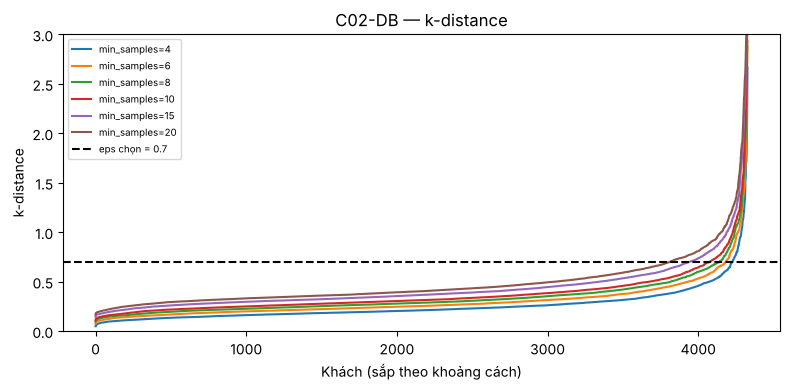

In [6]:
dbs = DBSCAN(eps=float(best["eps"]), min_samples=int(best["min_samples"])).fit(Z)
labels = dbs.labels_
core = labels != -1
print("Số khách mỗi cụm (-1 = nhiễu):", {int(k): int(v) for k, v in zip(*np.unique(labels, return_counts=True))})

# Đồ thị k-distance để đối chiếu với eps đã chọn
fig, ax = plt.subplots(figsize=(8, 4))
for ms in MIN_SAMPLES_GRID:
    d = NearestNeighbors(n_neighbors=ms).fit(Z).kneighbors(Z)[0][:, -1]
    ax.plot(np.sort(d), label=f"min_samples={ms}")
ax.axhline(float(best["eps"]), color="black", ls="--", label=f"eps chọn = {best['eps']}")
ax.set_ylim(0, 3); ax.set_xlabel("Khách (sắp theo khoảng cách)"); ax.set_ylabel("k-distance"); ax.legend(fontsize=7)
ax.set_title("C02-DB — k-distance"); plt.tight_layout(); plt.savefig(FIG / "k_distance.png", dpi=150); plt.show()

## Hồ sơ cụm (trung vị trên thang gốc)

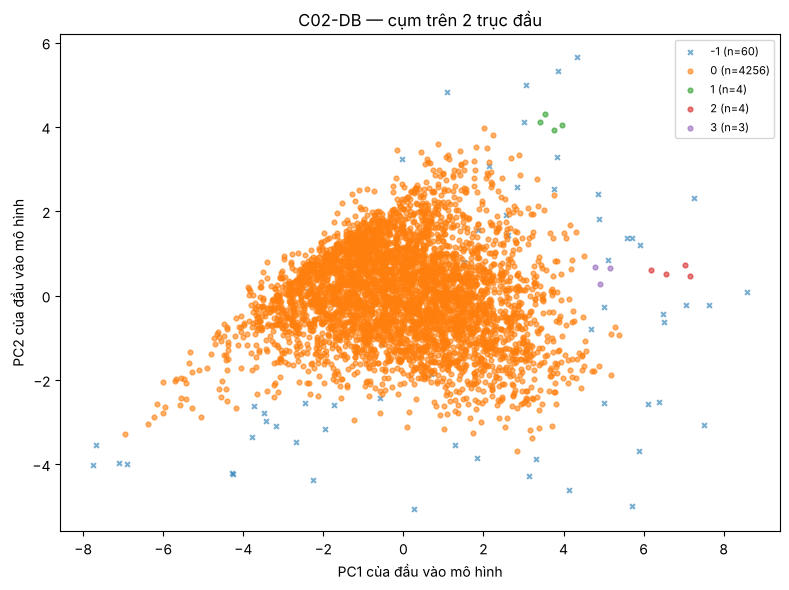

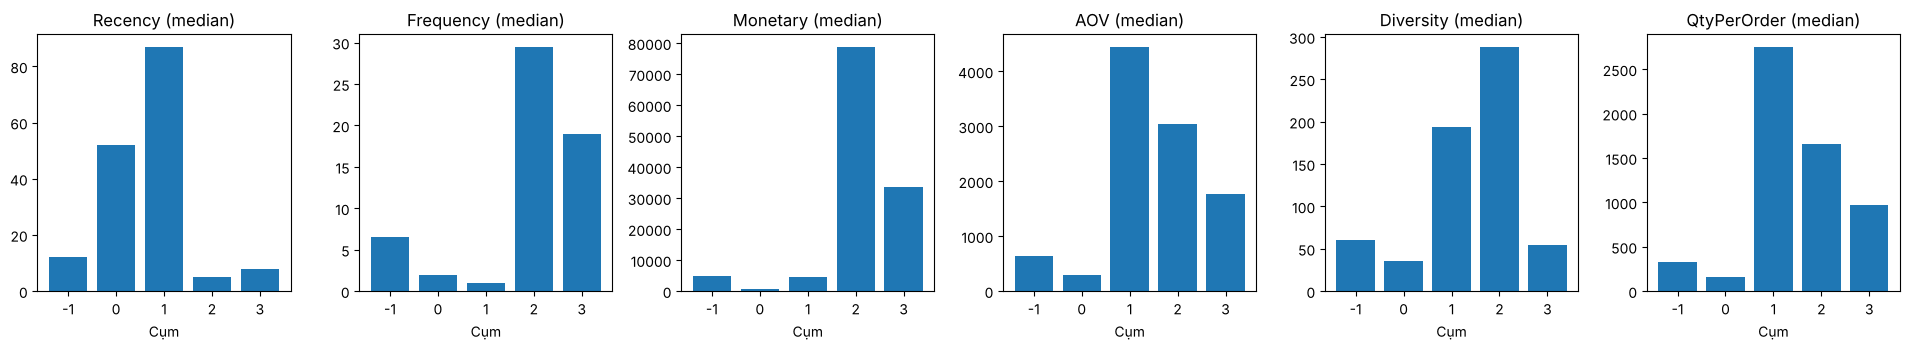

,customers,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,,
-1,60,12.0,6.5,4879.0,636.0,60.0,323.0,1.4,20.3
0,4256,52.0,2.0,653.2,285.4,35.0,160.0,98.4,73.5
1,4,87.0,1.0,4449.3,4449.3,194.0,2754.5,0.1,0.2
2,4,5.0,29.5,78858.0,3035.2,288.5,1658.0,0.1,4.8
3,3,8.0,19.0,33643.1,1770.7,54.0,966.7,0.1,1.2


In [7]:
agg = {f: (f, "median") for f in FEATURES}
prof = X.assign(cluster=labels).groupby("cluster").agg(customers=("Monetary", "size"), Monetary_sum=("Monetary", "sum"), **agg)
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum").round(1)

coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z) if Z.shape[1] > 2 else Z
fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(np.unique(labels)):
    m = labels == c
    ax.scatter(coords[m, 0], coords[m, 1], s=12, alpha=0.6, marker="x" if c == -1 else "o", label=f"{c} (n={m.sum()})")
ax.set_xlabel("PC1 của đầu vào mô hình"); ax.set_ylabel("PC2 của đầu vào mô hình"); ax.legend(fontsize=8)
ax.set_title("C02-DB — cụm trên 2 trục đầu")
plt.tight_layout(); plt.savefig(FIG / "dbscan_clusters_pca.png", dpi=150); plt.show()

# Trung vị từng biến theo cụm (thang gốc)
fig, axes = plt.subplots(1, len(FEATURES), figsize=(3.2 * len(FEATURES), 3.6))
for ax, f in zip(axes, FEATURES):
    ax.bar(prof.index.astype(str), prof[f]); ax.set_title(f + " (median)"); ax.set_xlabel("Cụm")
plt.tight_layout(); plt.savefig(FIG / "feature_comparison.png", dpi=150); plt.show()
prof

**Nhận xét:** Cụm 2 có Monetary trung vị cao nhất (78,858), gồm 4 khách (0.1%) nhưng chiếm 4.8% tổng Monetary. Cụm 0 đông nhất (98.4% khách, Recency trung vị 52 ngày). Nhóm nhiễu (-1) có 60 khách, chiếm 20.3% tổng Monetary. Một cụm chiếm ≥ 90% khách, nên kết quả chỉ phân biệt nhóm ngoại lai với số đông, chưa phải phân khúc khách hàng chi tiết.

## Đối chiếu với C01 (cùng tham số model)

In [8]:
# Chẩn đoán so với C01: giữ NGUYÊN tham số mô hình đã chọn, chỉ đổi tập feature về cấu hình C01 (FEATURES_PARENT).
# Đây không phải C01 được tune riêng, chỉ để đo riêng tác động của việc thêm feature.
prep_parent = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, validate=True)),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Zp = prep_parent.fit_transform(X[FEATURES_PARENT].values)
lp = DBSCAN(eps=float(best["eps"]), min_samples=int(best["min_samples"])).fit_predict(Zp)
ari_parent = adjusted_rand_score(labels, lp)
same_dims = Zp.shape[1] == Z.shape[1] and FEATURES_PARENT == FEATURES
same_geometry = same_dims and np.allclose(np.linalg.norm(Z[:300, None] - Z[None, :300], axis=2),
                                          np.linalg.norm(Zp[:300, None] - Zp[None, :300], axis=2), atol=1e-8)
print(f"C02: {Z.shape[1]} chiều | C01: {Zp.shape[1]} chiều")
print(f"ARI giữa nhãn C02 và nhãn C01 (cùng tham số): {ari_parent:.4f}")
print("Cùng hình học khoảng cách:", same_geometry)

C02: 3 chiều | C01: 3 chiều
ARI giữa nhãn C02 và nhãn C01 (cùng tham số): 0.7797
Cùng hình học khoảng cách: False


**Nhận xét:** ARI giữa C02 và C01 (cùng tham số) = 0.7797; số chiều đầu vào 3 so với 3. Nhãn khác một phần: việc thêm feature có tác động vừa phải.

## Lưu kết quả

In [9]:
res.to_csv(OUT / "dbscan_c02_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "dbscan_c02_labels.csv", index=False)
params = {"experiment": "C02-DB", "features": FEATURES, "feature_sources": {k: v for v, k in RENAME.items() if k in FEATURES}, "transform": 'log1p',
          "scaler": "StandardScaler", "pca": 0.9,
          "n_components": int(Z.shape[1]), "n_customers": int(len(X)),
          "pca_variance_kept": float(prep["pca"].explained_variance_ratio_.sum()),
          "eps": float(best["eps"]), "min_samples": int(best["min_samples"]), "n_clusters": int(best["n_clusters"]),
          "noise_pct": float(best["noise_pct"]), "largest_pct": float(best["largest_pct"]), "smallest": int(best["smallest"]),
          "silhouette_non_noise": float(best["silhouette"]), "dbi_non_noise": float(best["dbi"]),
          "ari_vs_parent_fixed_params": {"parent": "C01", "ari": float(ari_parent)}}
json.dump(params, open(OUT / "dbscan_c02_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_c02_grid.csv', 'dbscan_c02_labels.csv', 'dbscan_c02_params.json']


**Lưu ý:** DBSCAN không có `predict` cho khách mới, `labels_` chỉ áp dụng đúng 4.327 khách và đúng thứ tự khi fit, nên không lưu file model.

**Kết luận C02-DB:** DBSCAN eps=0.7, min_samples=4: 4 cụm, nhiễu 1.39%. ARI với C01 (cùng tham số) = 0.7797. Silhouette giữa các cấu hình khác không gian đầu vào (số chiều, scaler) không so sánh trực tiếp được; dùng ARI và hồ sơ cụm trên thang gốc để so sánh.